# Black–Scholes：解析解与三种神经求解器

比较充分状态 PINN、LSTM–PINN 和路径 Signature–LSTM–BSDE，覆盖浮动执行价回望、向上敲出和向下敲出期权。

**三方法对比为历史 100 轮演示；末尾另有保留 MC 锚点、训练 10,001 轮的充分状态障碍 PINN 复核。均需结合独立误差判断收敛。** 数学推导和实验限制见 [summary.md](summary.md)，运行与输出说明见 [README.md](README.md)。

| 方法 | 输入与网络 | 训练约束 |
|---|---|---|
| state_pinn | 充分状态 + MLP | PDE、终端、边界 |
| lstm_pinn | 原始路径 + LSTM | 实验性 PDE 风格残差、终端等 |
| signature_bsde | 分段 logsignature + LSTM | BSDE、终端 |

下方历史短训练配置显式关闭 MC 锚点；当前入口对充分状态障碍 PINN 已恢复默认权重 100，末尾单独复核。当前 LSTM–PINN 的时间差分不能直接解释为严格 PPDE 水平导数；BSDE 使用离散监控支付。三者尚不能视作完全相同的离散问题。

In [1]:
from pathlib import Path
import json
import subprocess
import sys

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "scripts" / "run_comparison.py").is_file():
    raise RuntimeError("请从项目根目录打开并运行这个 notebook。")
from scripts.report import plot_results

local_python = ROOT / ".venv_signatory" / "Scripts" / "python.exe"
TRAIN_PYTHON = str(local_python) if local_python.exists() else sys.executable
OUTPUT = ROOT / "outputs" / "notebook_demo"
CONFIG = dict(products=["lookback", "barrier_upout", "barrier_downout"],
              epochs=100, batch_size=64, steps=32, lag=4,
              mc_paths=8192, eval_paths=128, seeds=[1],
              option_type="call", s0=1.0, r=0.03, sigma=0.4, T=1.0,
              strike=1.0, up_barrier=1.2, down_barrier=0.8,
              mc_anchor_weight=0.0)
# 正式实验可增加 epochs、steps、mc_paths 和 seeds，并指定新的 OUTPUT。
CONFIG

{'products': ['lookback', 'barrier_upout', 'barrier_downout'],
 'epochs': 100,
 'batch_size': 64,
 'steps': 32,
 'lag': 4,
 'mc_paths': 8192,
 'eval_paths': 128,
 'seeds': [1],
 'option_type': 'call',
 's0': 1.0,
 'r': 0.03,
 'sigma': 0.4,
 'T': 1.0,
 'strike': 1.0,
 'up_barrier': 1.2,
 'down_barrier': 0.8,
 'mc_anchor_weight': 0.0}

In [2]:
if not (OUTPUT / "comparison.csv").is_file():
    command = [sys.executable, "-m", "scripts.run_comparison",
               "--python", TRAIN_PYTHON, "--output-dir", str(OUTPUT)]
    for key, value in CONFIG.items():
        command.append("--" + key.replace("_", "-"))
        command.extend(str(item) for item in (value if isinstance(value, list) else [value]))
    result = subprocess.run(command, cwd=ROOT, capture_output=True, text=True)
    if result.returncode:
        raise RuntimeError(result.stdout + result.stderr)
    print("已完成三种方法训练。")
else:
    print("读取已保存的实验结果。")

actual_config = json.loads((OUTPUT / "config.json").read_text(encoding="utf-8"))
if actual_config["status"] != "complete":
    raise RuntimeError("实验尚未完成，请检查日志并更换新的输出目录后重试。")
mismatches = {key: (actual_config.get(key), value) for key, value in CONFIG.items()
              if actual_config.get(key) != value}
if mismatches:
    raise RuntimeError(f"已保存结果与当前配置不同，请更换 OUTPUT：{mismatches}")
display(pd.Series({key: actual_config[key] for key in CONFIG}, name="实际运行配置"))

读取已保存的实验结果。


products            [lookback, barrier_upout, barrier_downout]
epochs                                                     100
batch_size                                                  64
steps                                                       32
lag                                                          4
mc_paths                                                  8192
eval_paths                                                 128
seeds                                                      [1]
option_type                                               call
s0                                                         1.0
r                                                         0.03
sigma                                                      0.4
T                                                          1.0
strike                                                     1.0
up_barrier                                                 1.2
down_barrier                                           

## 解析价格与公共 Monte Carlo 对照

参考 MC 使用独立随机种子并分批模拟。离散 MC 只监控网格点；障碍产品另外使用 Brownian bridge 条件存续概率计算连续监控对照。`*_mc_se` 为 MC 标准误，约 95% 的正态近似区间为估值 ± 1.96 × 标准误。回望 MC 极值仍在网格上计算。

所有参考价格只用于统一入口的评估，默认不作为网络训练标签。

In [3]:
references = json.loads((OUTPUT / "references.json").read_text(encoding="utf-8"))
display(pd.DataFrame(references).T)

,continuous_analytic,paths,steps,seed,monitoring,discrete_mc,discrete_mc_se,bridge_mc,bridge_mc_se
lookback,0.292178,8192,32,1729,grid; bridge additionally available for barriers,0.261751,0.003401,NaN,NaN
barrier_upout,0.001971,8192,32,1729,grid; bridge additionally available for barriers,0.00374,0.00022,0.001818,0.000122
barrier_downout,0.143819,8192,32,1729,grid; bridge additionally available for barriers,0.153212,0.003336,0.143578,0.003254


## 三种方法的价格与误差

下表按每次运行保存原始价格、连续解析误差和训练时间。`relative_error` 是比例，显示时转换为百分数。解析价为零时相对误差没有定义。耗时包含方法内训练和本地评估，不包含子进程启动、外部公共参考计算和绘图。

In [4]:
results, figure_paths = plot_results(OUTPUT)
columns = ["product", "method", "seed", "prediction", "continuous_analytic",
           "absolute_error", "relative_error", "elapsed_seconds", "mc_anchor_weight"]
display(results[columns].style.format({"prediction": "{:.8f}", "continuous_analytic": "{:.8f}",
        "absolute_error": "{:.8f}", "relative_error": "{:.2%}", "elapsed_seconds": "{:.2f}"}, na_rep="N/A"))
aggregate = results.groupby(["product", "method"])[["prediction", "absolute_error", "relative_error"]].agg(["mean", "std", "count"])
display(aggregate)
# 单 seed 的 std 为 NaN；增加 seeds 后再解释训练稳定性。

,product,method,seed,prediction,continuous_analytic,absolute_error,relative_error,elapsed_seconds,mc_anchor_weight
0,lookback,state_pinn,1,0.20582430,0.29217778,0.08635348,29.56%,0.59,0.000000
1,lookback,lstm_pinn,1,0.19743322,0.29217778,0.09474456,32.43%,2.33,0.000000
2,lookback,signature_bsde,1,0.38743415,0.29217778,0.09525638,32.60%,0.70,0.000000
3,barrier_upout,state_pinn,1,0.00002065,0.00197072,0.00195007,98.95%,0.45,0.000000
4,barrier_upout,lstm_pinn,1,0.00066549,0.00197072,0.00130523,66.23%,2.24,0.000000
5,barrier_upout,signature_bsde,1,0.00369871,0.00197072,0.00172799,87.68%,0.77,0.000000
6,barrier_downout,state_pinn,1,0.16464064,0.14381884,0.02082180,14.48%,0.44,0.000000
7,barrier_downout,lstm_pinn,1,0.08415575,0.14381884,0.05966309,41.48%,2.53,0.000000
8,barrier_downout,signature_bsde,1,0.17272784,0.14381884,0.02890900,20.10%,0.73,0.000000


prediction           absolute_error            \
                                     mean std count           mean std count   
product         method                                                         
barrier_downout lstm_pinn        0.084156 NaN     1       0.059663 NaN     1   
                signature_bsde   0.172728 NaN     1       0.028909 NaN     1   
                state_pinn       0.164641 NaN     1       0.020822 NaN     1   
barrier_upout   lstm_pinn        0.000665 NaN     1       0.001305 NaN     1   
                signature_bsde   0.003699 NaN     1       0.001728 NaN     1   
                state_pinn       0.000021 NaN     1       0.001950 NaN     1   
lookback        lstm_pinn        0.197433 NaN     1       0.094745 NaN     1   
                signature_bsde   0.387434 NaN     1       0.095256 NaN     1   
                state_pinn       0.205824 NaN     1       0.086353 NaN     1   

                               relative_error            
                                         mean std count  
product         method                                   
barrier_downout lstm_pinn            0.414849 NaN     1  
                signature_bsde       0.201010 NaN     1  
                state_pinn           0.144778 NaN     1  
barrier_upout   lstm_pinn            0.662312 NaN     1  
                signature_bsde       0.876828 NaN     1  
                state_pinn           0.989520 NaN     1  
lookback        lstm_pinn            0.324270 NaN     1  
                signature_bsde       0.326022 NaN     1  
                state_pinn           0.295551 NaN     1

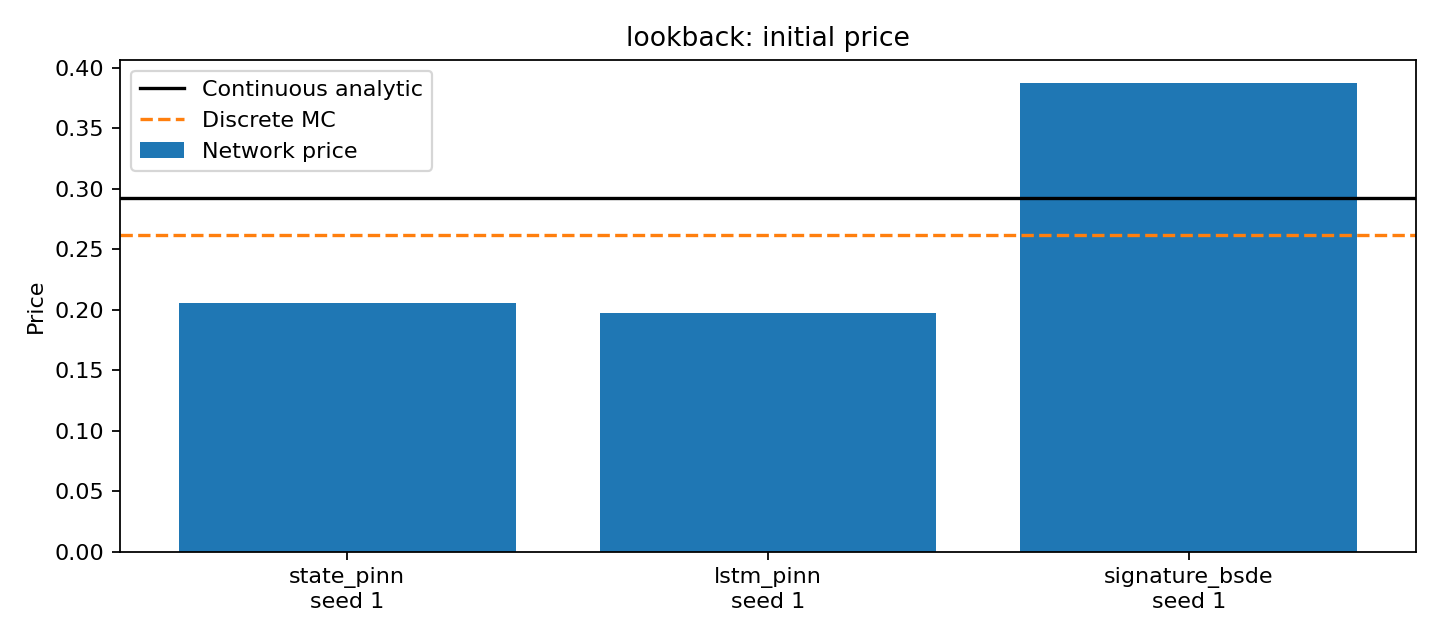

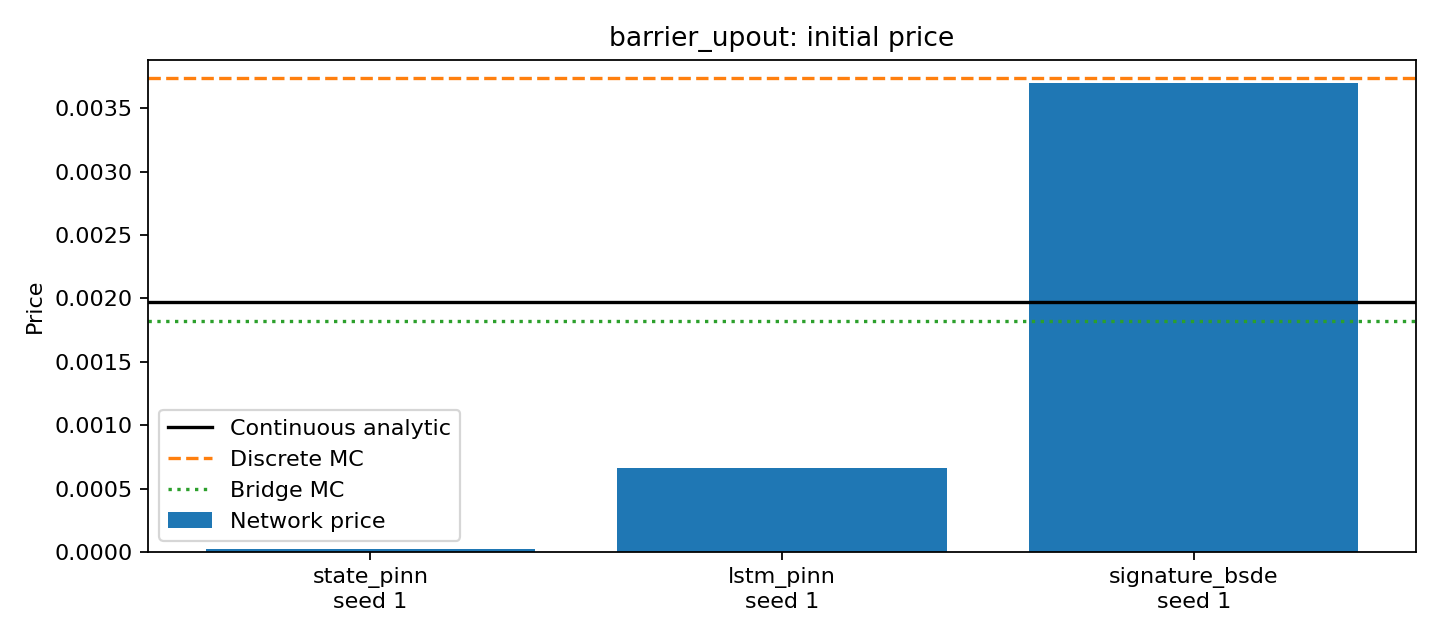

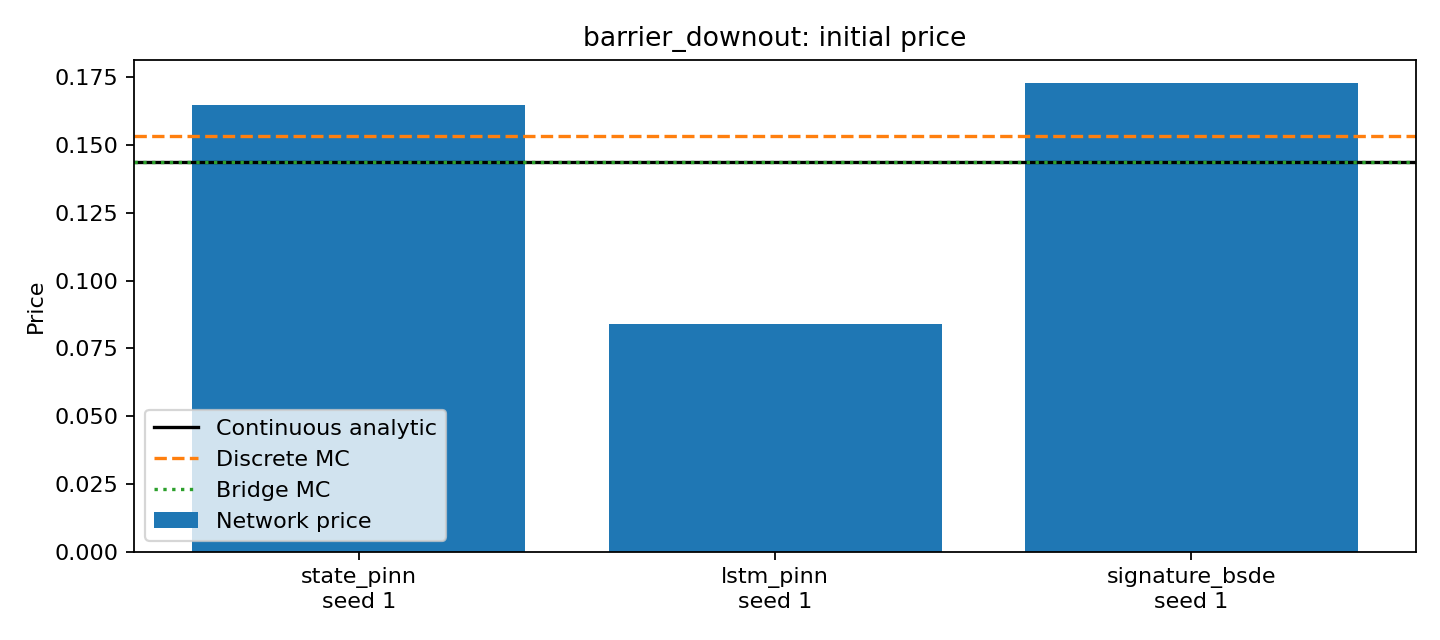

In [5]:
for path in figure_paths:
    if path.name.endswith("_prices.png"):
        display(Image(filename=str(path)))

## 每轮训练 loss

按方法分别画总 loss 和各损失分量。图中的分量为加权前原始值，总 loss 使用各方法自己的权重；三种方法总 loss 的数值大小不具有直接可比性。恒为零的分量和关闭的 MC 锚点不画在图中。

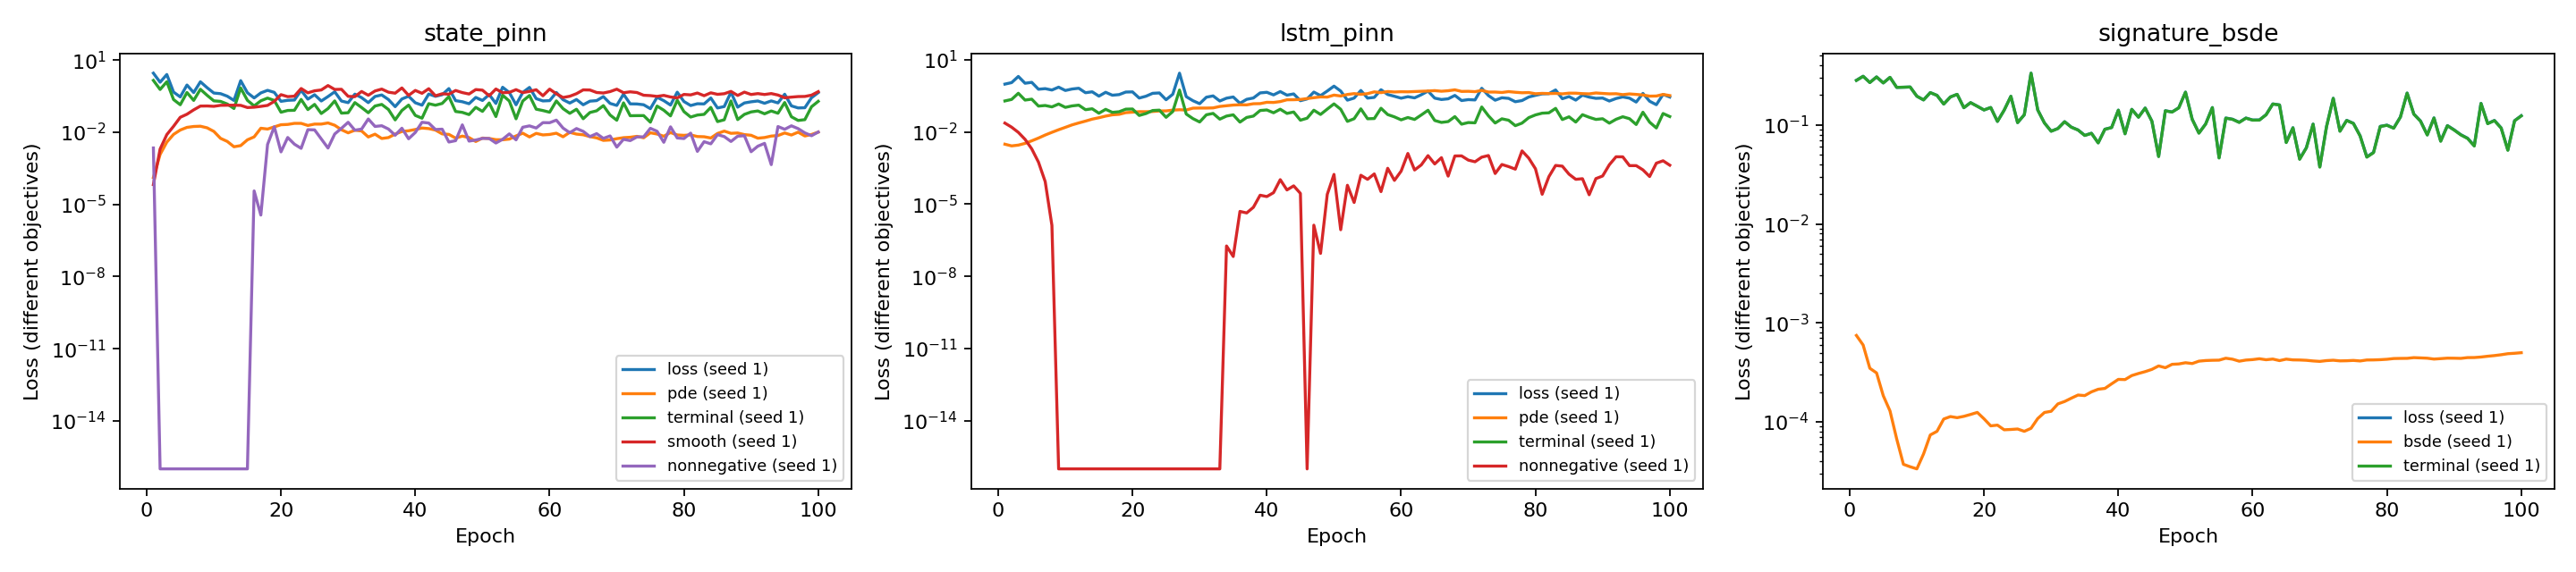

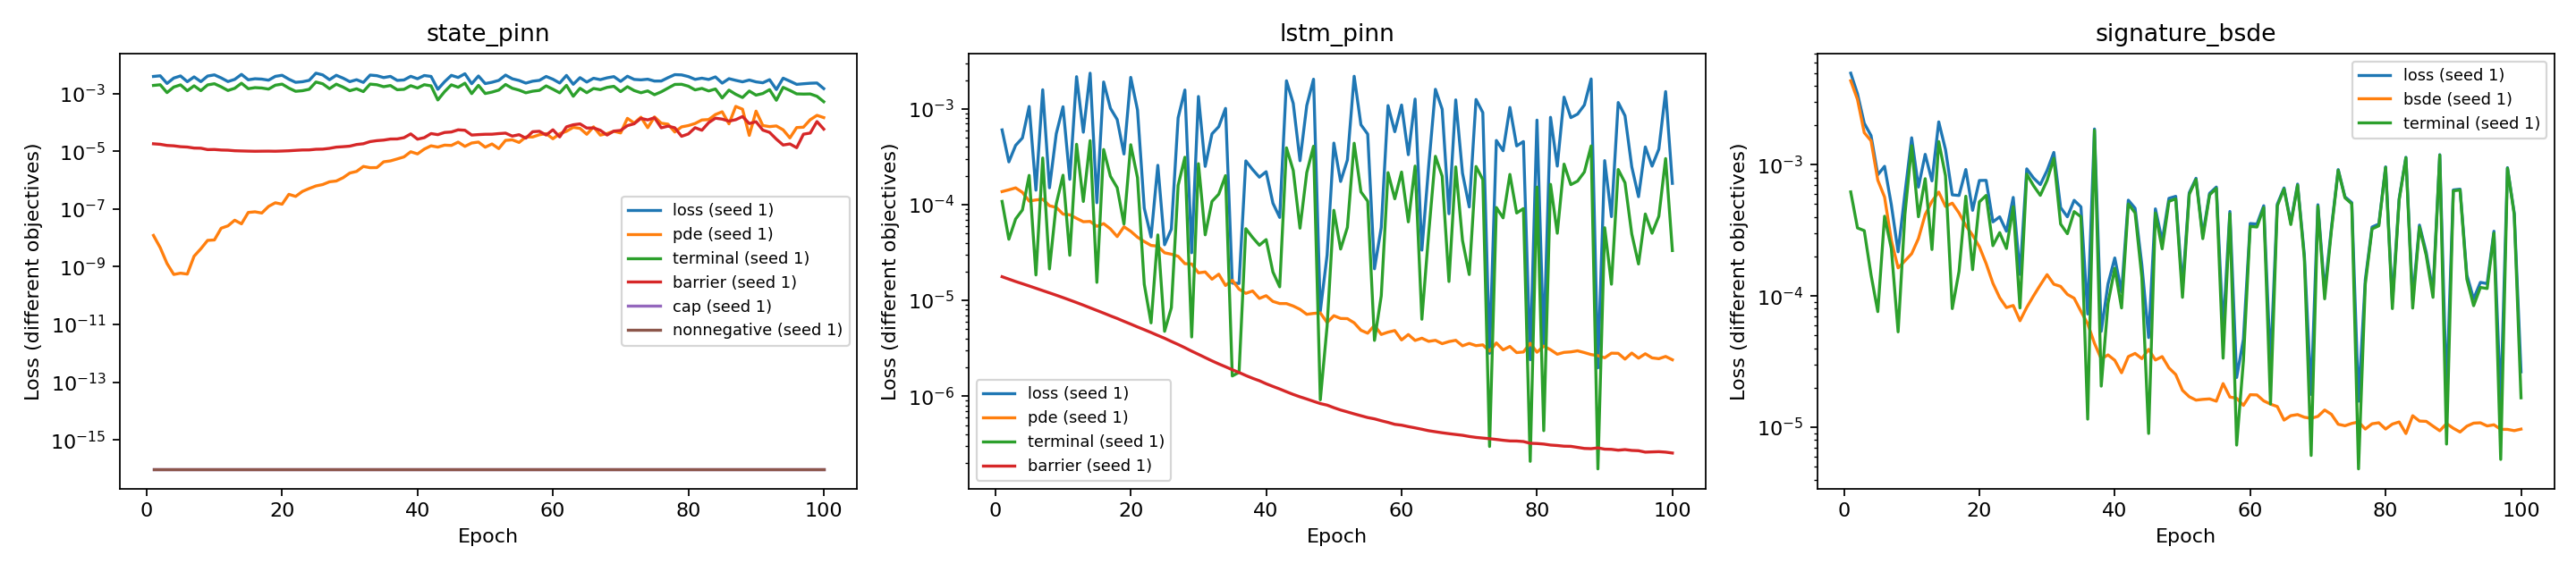

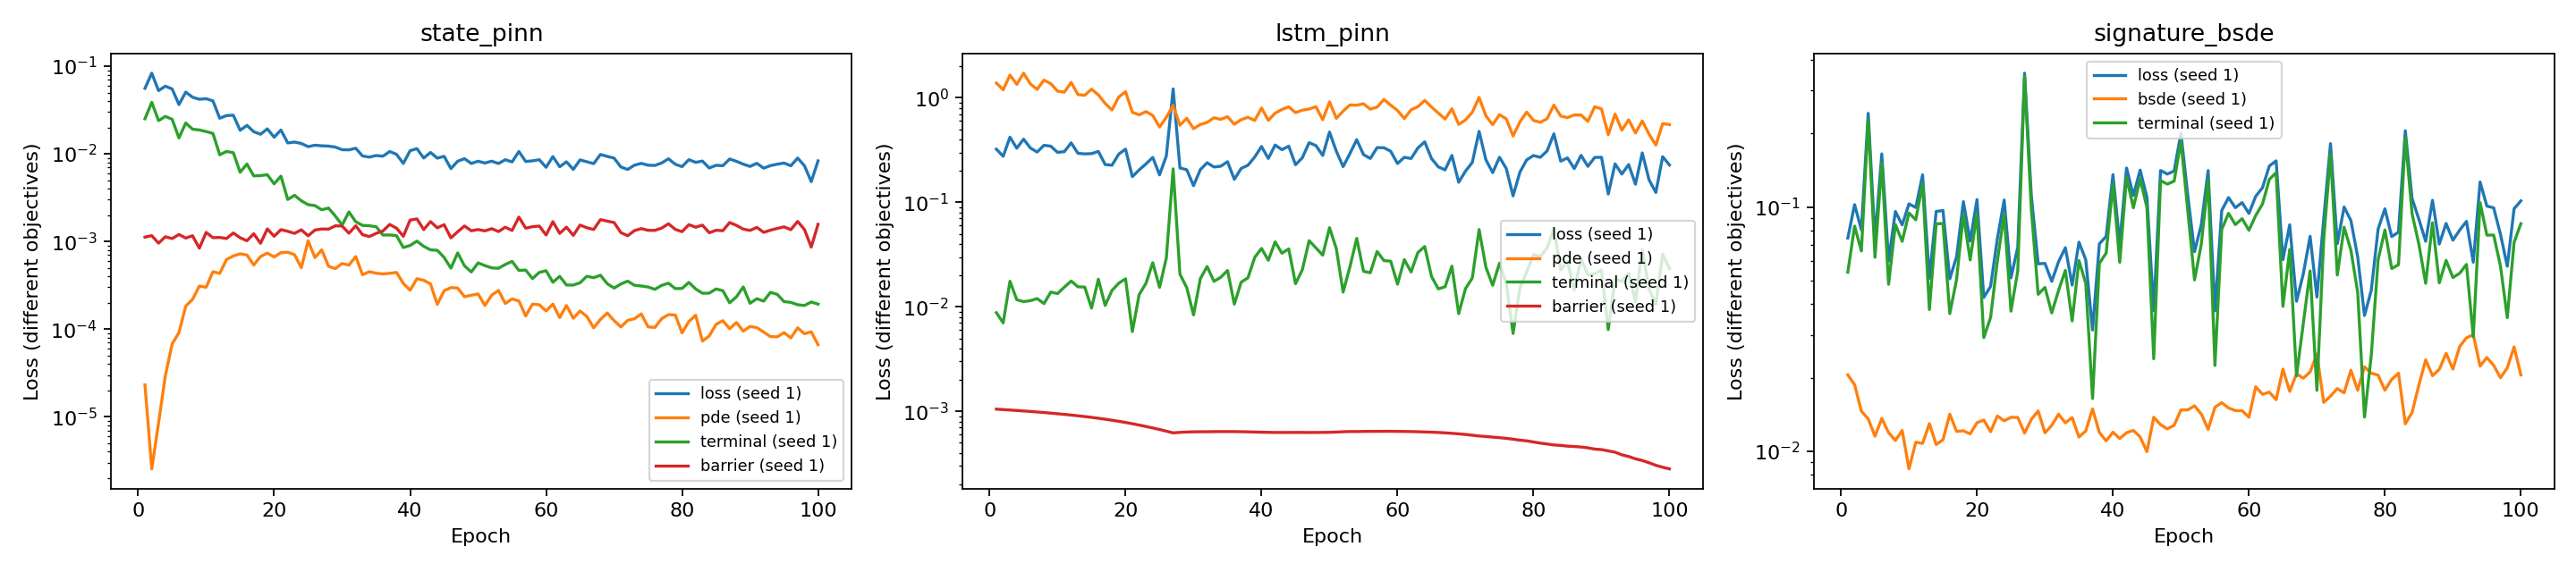

In [6]:
for path in figure_paths:
    if path.name.endswith("_losses.png"):
        display(Image(filename=str(path)))

## 结果解读

- 本次运行只验证训练、保存和绘图流程；100 轮及单随机种子不足以比较方法优劣。
- 连续解析价与离散监控支付之间存在偏差。尤其障碍产品，需要结合离散 MC 与 bridge MC 解释网络误差。
- 各方法使用相同市场、epoch、batch 和模拟网格，但网络规模、损失权重及计算成本不同。各运行的 `metrics.json` 保存完整超参数。
- LSTM–PINN 保留现有实验残差，尚未证明其等价于严格 PPDE。充分状态 PINN 不需要学习历史压缩。
- 下一步可固定市场运行多 seed、增加训练预算，并对 `steps/lag` 做网格收敛比较。价格精度和对冲精度还需分别验证。

完整输出保存在 `outputs/notebook_demo/`，包括 `comparison.csv`、公共参考价格、逐轮 `history.csv`、配置、日志、模型参数，以及 `figures/` 中的 PNG。Git 默认忽略本地输出；本 notebook 嵌入展示结果。

## 充分状态障碍 PINN：10,001 轮复核

这一部分只查看充分状态 PINN，不涉及 LSTM。保留原算法和 MC 起始锚点，使用 batch 128、200,000 条 MC 路径。价格和网格误差为单 seed 的实测结果；近到期边界误差仍需单独检查。

下面读取已保存的运行；没有结果时请先执行 README 的充分状态命令。

,product,prediction,continuous_analytic,relative_error,mc_anchor_weight,elapsed_seconds
0,barrier_upout,0.00191156,0.00197072,3.00%,100.000000,56.85
1,barrier_downout,0.14352109,0.14381884,0.21%,100.000000,57.75


,product,points,surface_relative_l2,surface_rmse,boundary_rmse,boundary_max_absolute_error,terminal_rmse
0,barrier_upout,30,0.136045,0.000986,0.010115,0.024578,0.044608
1,barrier_downout,29,0.001438,0.000939,0.002619,0.004276,0.000180


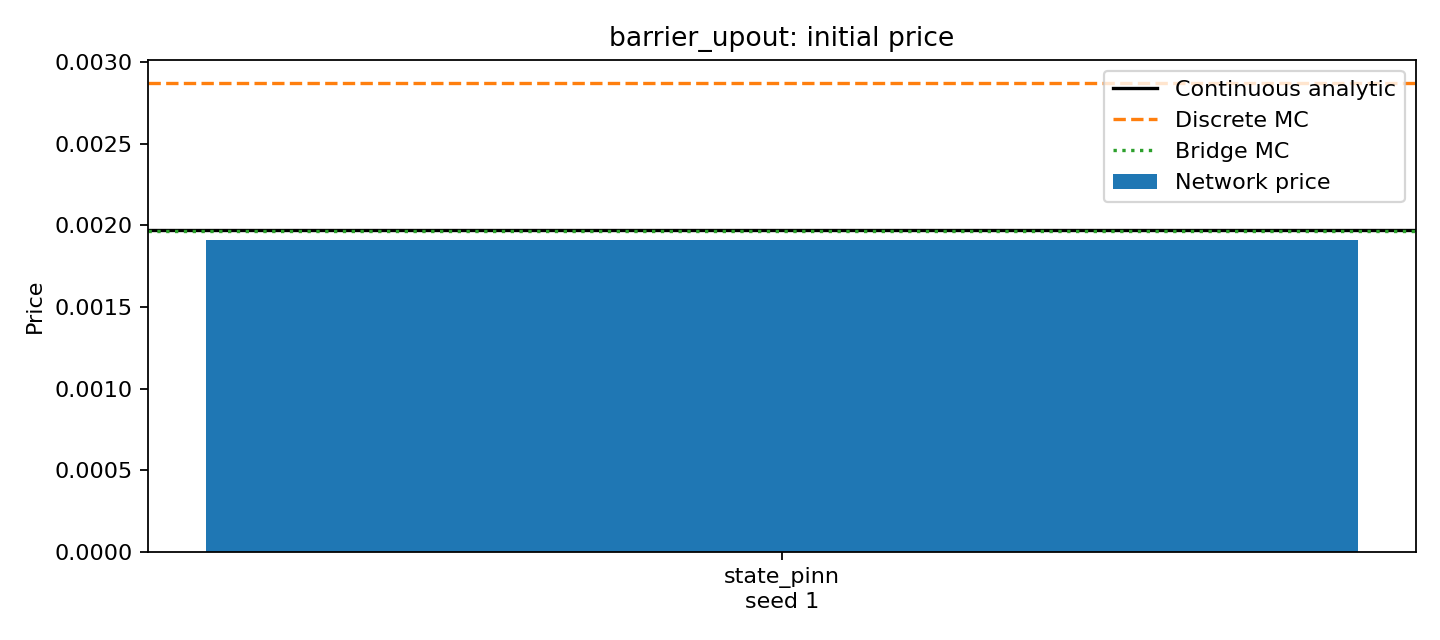

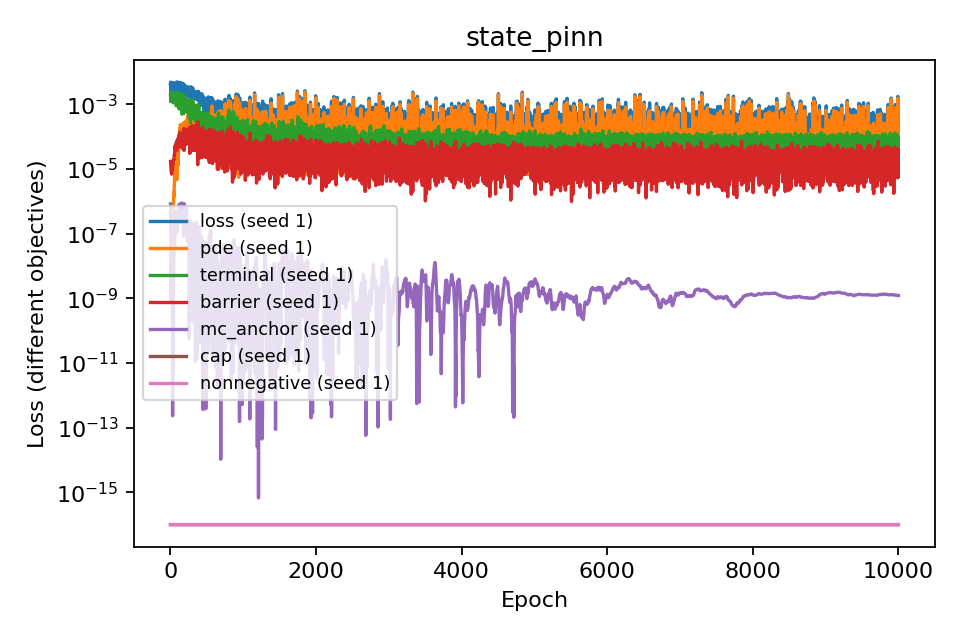

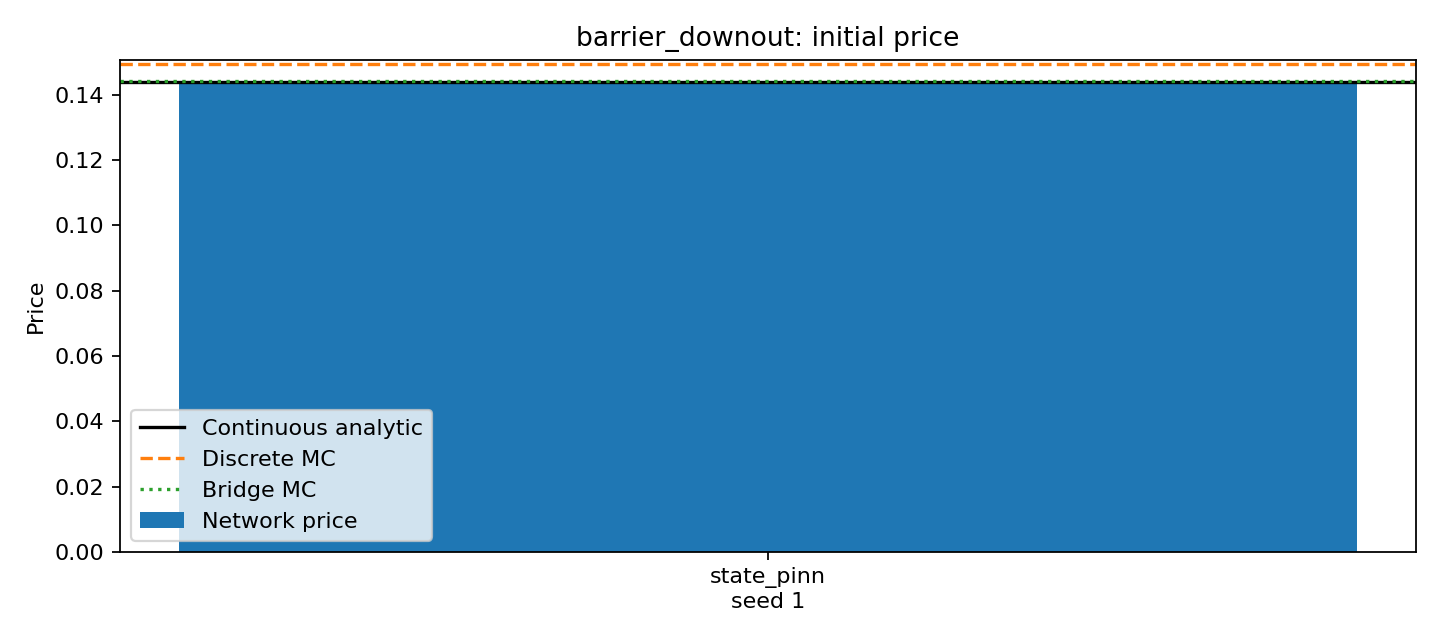

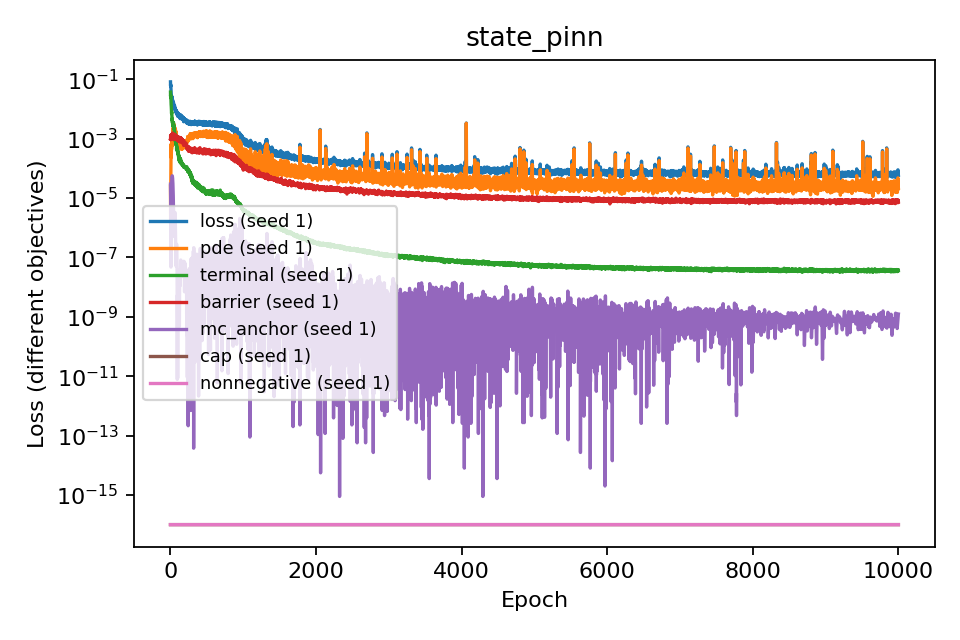

In [7]:
STATE_OUTPUT = ROOT / "outputs" / "state_pinn_review"
if (STATE_OUTPUT / "comparison.csv").is_file():
    state_results, state_figures = plot_results(STATE_OUTPUT)
    display(state_results[["product", "prediction", "continuous_analytic", "relative_error", "mc_anchor_weight", "elapsed_seconds"]].style.format({
        "prediction": "{:.8f}", "continuous_analytic": "{:.8f}",
        "relative_error": "{:.2%}", "elapsed_seconds": "{:.2f}"}))
    state_validation = []
    for row in state_results.itertuples():
        item = json.loads((STATE_OUTPUT / row.run_dir / "validation.json").read_text(encoding="utf-8"))
        item["product"] = row.product
        state_validation.append(item)
    display(pd.DataFrame(state_validation)[["product", "points", "surface_relative_l2", "surface_rmse", "boundary_rmse", "boundary_max_absolute_error", "terminal_rmse"]])
    for path in state_figures:
        display(Image(filename=str(path)))
else:
    print("尚无充分状态复核结果，请运行 README 中的 state_pinn 命令。")

初始价格误差约为向上敲出 3.00%、向下敲出 0.21%；独立状态网格的相对 L2 误差约为 13.60%、0.14%。向上敲出的近到期障碍边界和终端误差仍明显，不能把初始锚点接近解析价当成整个价格函数已收敛。

surface_validation.csv 保存每个状态的预测与解析价，validation.json 保存独立网格、障碍边界及终端误差。前面的 LSTM–PINN、Signature–BSDE 历史演示未作算法修改。

## 向上敲出：只补全终端采样的对照

网络、PDE/边界采样、权重和随机种子保持不变，均训练 10,001 轮。新终端采样覆盖原来遗漏的 1.14～1.2 区间。full 是可选实验，默认仍为 legacy；本次结果尚未证明它能整体改善求解。

,sampler,initial_price,initial_relative_error,surface_relative_l2,terminal_rmse,boundary_rmse,boundary_max,omitted_strip_terminal_rmse
0,legacy,0.00191156,3.00%,13.60%,0.044608,0.010115,0.024578,0.098146
1,full,0.00186592,5.32%,21.53%,0.020752,0.028820,0.070413,0.050508


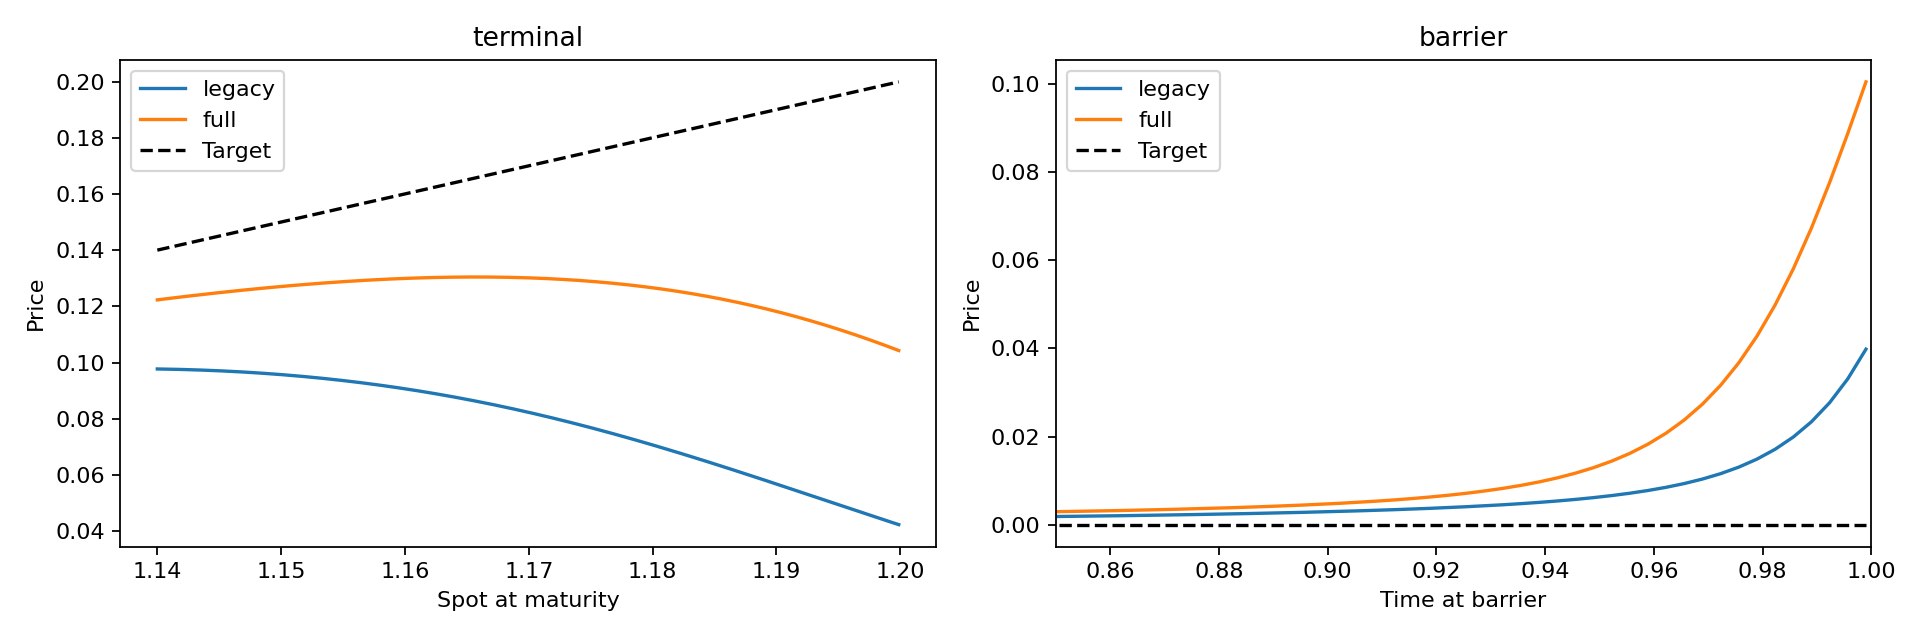

In [8]:
ABLATION = ROOT / "outputs" / "state_pinn_terminal_sampling" / "barrier_upout" / "state_pinn" / "seed_1"
if (ABLATION / "terminal_sampling_comparison.csv").is_file():
    ablation = pd.read_csv(ABLATION / "terminal_sampling_comparison.csv")
    display(ablation.style.format({"initial_price": "{:.8f}",
        "initial_relative_error": "{:.2%}", "surface_relative_l2": "{:.2%}",
        "terminal_rmse": "{:.6f}", "boundary_rmse": "{:.6f}",
        "boundary_max": "{:.6f}", "omitted_strip_terminal_rmse": "{:.6f}"}))
    import matplotlib.pyplot as plt
    curves = pd.read_csv(ABLATION / "terminal_sampling_curves.csv")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, kind, xlabel in zip(axes, ["terminal", "barrier"], ["Spot at maturity", "Time at barrier"]):
        group = curves[curves.kind == kind]
        for sampler, part in group.groupby("sampler", sort=False):
            ax.plot(part.x, part.prediction, label=sampler)
        target = group[group.sampler == "legacy"]
        ax.plot(target.x, target.target, color="black", linestyle="--", label="Target")
        ax.set(xlabel=xlabel, ylabel="Price", title=kind)
        ax.legend()
    axes[1].set_xlim(.85, 1.)
    fig.tight_layout()
    (ABLATION / "figures").mkdir(exist_ok=True)
    figure = ABLATION / "figures" / "terminal_boundary_comparison.png"
    fig.savefig(figure, dpi=160)
    plt.close(fig)
    display(Image(filename=str(figure)))
else:
    print("请先运行 README 中的终端采样单项对照；此处展示已归档实验的比较数据。")

终端拟合改善，但边界和内部价格变差，所以暂不替换默认配置。下一步应隔离验证 PDE 采样仍未覆盖的近障碍区域，不同时改变多个因素。

## PDE 采样范围：相同安全差分的对照

两组均补全终端采样，并使用相同双精度 PDE 差分及不越界空间步长。模型参数、网络、种子、损失权重和 10,001 轮预算相同；只改变 PDE 的采样范围。图中的解析线连接固定网格点，不代表已验证整个连续状态域。

,label,initial_relative_error,surface_relative_l2,terminal_rmse,boundary_rmse
0,Original PDE range,5.32%,21.53%,0.020752,0.028820
1,Full PDE range,2.65%,67.04%,0.033032,0.031353


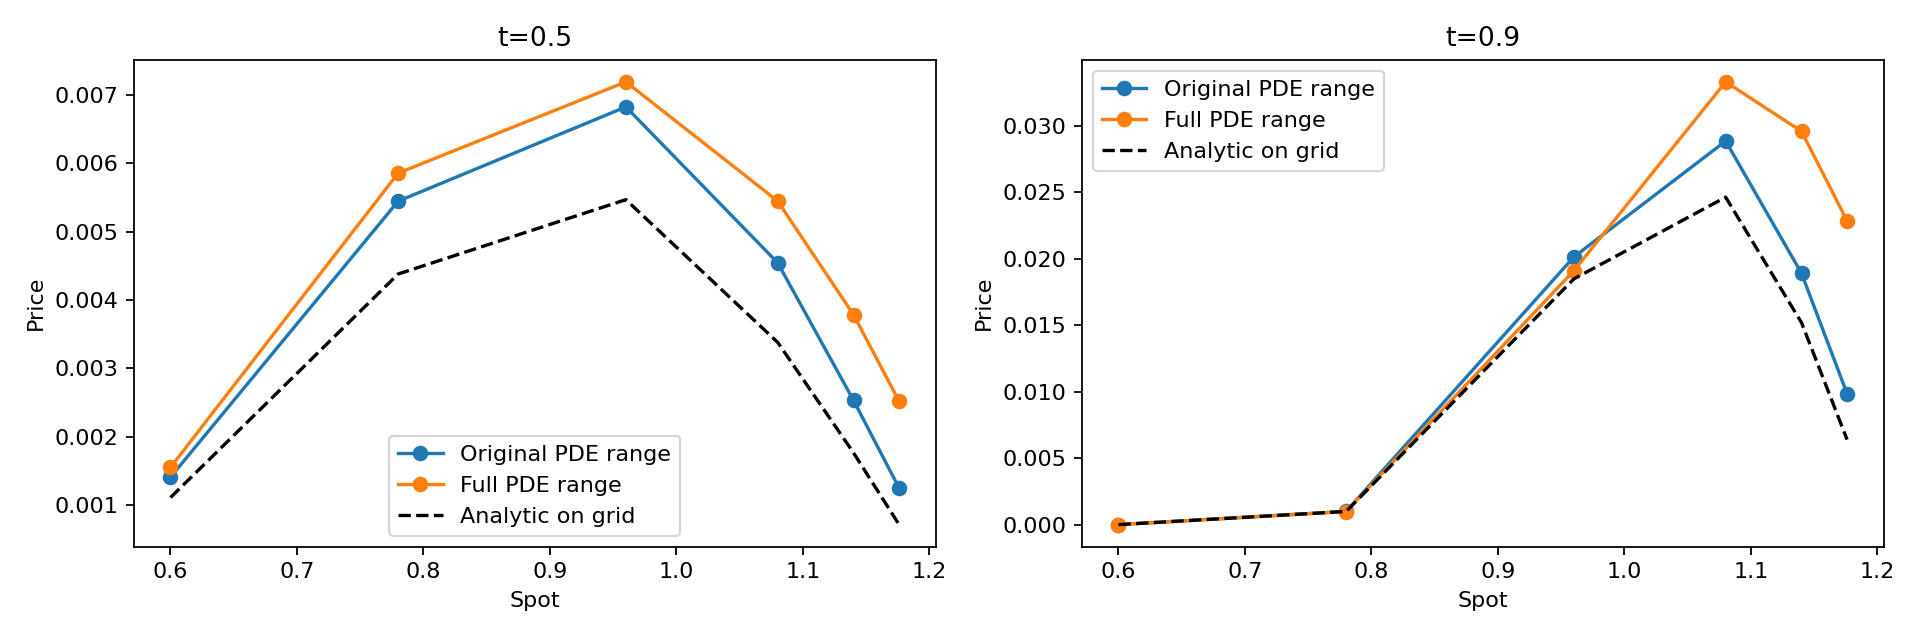

pde vs terminal       -0.771341
pde vs barrier         0.520896
terminal vs barrier   -0.944968
Name: Fixed-batch gradient cosines, dtype: float64

In [9]:
PDE_ROOTS = {
    "Original PDE range": ROOT / "outputs" / "state_pinn_pde_control",
    "Full PDE range": ROOT / "outputs" / "state_pinn_pde_full",
}
if all((path / "barrier_upout/state_pinn/seed_1/validation.json").is_file() for path in PDE_ROOTS.values()):
    pde_rows, pde_curves = [], {}
    for label, path in PDE_ROOTS.items():
        run = path / "barrier_upout/state_pinn/seed_1"
        data = json.loads((run / "validation.json").read_text(encoding="utf-8"))
        pde_rows.append(dict(label=label, **{key: data[key] for key in [
            "initial_relative_error", "surface_relative_l2", "terminal_rmse", "boundary_rmse"]}))
        pde_curves[label] = pd.read_csv(run / "surface_validation.csv")
    pde_comparison = pd.DataFrame(pde_rows)
    pde_output = PDE_ROOTS["Full PDE range"]
    pde_comparison.to_csv(pde_output / "pde_sampling_comparison.csv", index=False)
    display(pde_comparison.style.format({"initial_relative_error": "{:.2%}",
        "surface_relative_l2": "{:.2%}", "terminal_rmse": "{:.6f}", "boundary_rmse": "{:.6f}"}))
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, t in zip(axes, [.5, .9]):
        for label, curve in pde_curves.items():
            part = curve[(curve.t-t).abs() < 1e-8]
            ax.plot(part.spot, part.prediction, marker="o", label=label)
        truth = next(iter(pde_curves.values()))
        part = truth[(truth.t-t).abs() < 1e-8]
        ax.plot(part.spot, part.analytic, color="black", linestyle="--", label="Analytic on grid")
        ax.set(title=f"t={t}", xlabel="Spot", ylabel="Price")
        ax.legend()
    fig.tight_layout()
    (pde_output / "figures").mkdir(exist_ok=True)
    pde_figure = pde_output / "figures" / "pde_sampling_comparison.png"
    fig.savefig(pde_figure, dpi=160)
    plt.close(fig)
    display(Image(filename=str(pde_figure)))
    gradient_file = pde_output / "barrier_upout/state_pinn/seed_1/gradient_diagnostics.json"
    if gradient_file.exists():
        gradient_data = json.loads(gradient_file.read_text(encoding="utf-8"))
        display(pd.Series(gradient_data["cosines"], name="Fixed-batch gradient cosines"))
else:
    print("请先运行 README 中两组 PDE 采样对照命令。")

完整 PDE 覆盖没有带来整体改善。固定诊断批次上的终端与边界梯度几乎反向，说明当前训练未协调好两项约束；这不表示数学边界条件矛盾，也不是全部训练过程的因果证明。暂不改变默认配置，不继续叠加权重、网络或学习率修改。